# Cost-aware learned modality gate: full architecture

Per sample, decide **which subset of sensors to run** so that beam-prediction
accuracy is maximised under a compute budget.

```
 sample x_i ──► GPS expert f0 (always) ──► p0 ─┐
     │                                         ├─► learned gate h_θ ──► ĝ_i ∈ R^K (DBA gain per subset)
     └──────► sensor probes q_i (no encoder) ──┘            │
                                                            ▼
                               cost-aware selection  k* = argmax_k  ĝ_k − λ·C_k
                                 │                                   │
                       k* = 0: keep GPS beam            k* ≠ 0: run expert f_k*
                                                     (only the encoders in M_k*)
```

| Section | What it does |
|---|---|
| 3 | Runs the **expert bank** (GPS + every camera/LiDAR/radar subset) and collects the gate features: the GPS expert's uncertainty and **sensor-health probes** |
| 4 | Trains the **K-output gain-regression gate**, cross-fitted over contiguous temporal blocks |
| 5 | **Cost-aware selection**: sweeps λ to trace accuracy against average GFLOPs, compared with every fixed subset, a two-tier cascade, confidence routing and the oracle |
| 6 | **Sensor-health experiment**: a camera fault is injected into half the samples; does the gate route around it? |
| 7 | **Online router**: a real `route(sample)` that runs only the selected encoders, with measured latency |
| 8 | Plots and saved outputs |

**Attach before running** (Kaggle, GPU T4, Internet on):
1. The preprocessed DeepSense6G dataset (the one containing `index/samples.csv`).
2. The modality-ablation checkpoints (`gps.pt` / `gps/best.pt`, `gps_image…`, etc.).
   `gps` is required; every other checkpoint found becomes one expert in the bank.

`QUICK_RUN = True` uses 300 validation samples (a few minutes) to check the
pipeline. Set it to `False` for the full validation split.

## 1. Configuration

In [1]:
from pathlib import Path

QUICK_RUN = False         # True: 300 samples to check the pipeline. False: full run.
SPLIT = "val"
BATCH_SIZE = 32
WORKERS = 2
COLLECT_SENSOR_QUALITY = True   # sensor-health probes q_i from the raw camera/LiDAR/radar

# gate training: cross-fitting over contiguous temporal blocks
N_FOLDS = 5
BLOCK_FRAMES = 50
GATE_HIDDEN = 32
GATE_EPOCHS = 400
GATE_SEEDS = [0, 1, 2, 3, 4]    # ensemble of gates, predictions averaged

C_PROBE = 0.01                  # GFLOPs for the probes (simple reductions over raw tensors)
BUDGETS = [5.0, 12.0, 24.0, 48.0]   # GFLOPs budgets for the comparison table

# sensor-health experiment (section 6)
HEALTH_FAULT = ("image", "blur", 2.0)   # modality, kind, severity
HEALTH_FRAC = 0.5                       # share of samples given the fault

# online router demo (section 7)
N_ROUTER_DEMO = 50 if QUICK_RUN else 300

LIMIT = 300 if QUICK_RUN else None
OUT = Path("/kaggle/working/outputs/modality_gate")
(OUT / "plots").mkdir(parents=True, exist_ok=True)
print(f"QUICK_RUN={QUICK_RUN}  split={SPLIT}  limit={LIMIT}")

QUICK_RUN=False  split=val  limit=None


## 2. Environment, data, code

In [2]:
import os
import socket
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

print(f"torch {torch.__version__}   cuda: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_properties(0).name}")


def has_internet(host="github.com", port=443, timeout=6):
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False


assert has_internet(), "Internet is off; the code cannot be cloned."

torch 2.11.0+cu130   cuda: True
GPU: Tesla T4


In [3]:
import shutil

INPUT_ROOT = Path("/kaggle/input")
SOURCES = ("development", "adaptation", "test")


def walk_dirs(base, follow=True):
    for dirpath, dirnames, filenames in os.walk(base, followlinks=follow):
        yield Path(dirpath), dirnames, filenames


def find_source(base, name):
    for c in (base / name / name, base / name):
        if c.is_dir() and any(c.glob("scenario*")):
            return c
    return None


def find_index(base):
    hits = []
    for c in (base / "index" / "index", base / "index"):
        if (c / "samples.csv").exists():
            hits.append(c)
    for d, _dn, fn in walk_dirs(base):
        if "samples.csv" in fn and d not in hits:
            hits.append(d)
    if not hits:
        return None
    # prefer the index that sits beside the actual tensors, not a copy inside a
    # results dump
    score = lambda h: sum(1 for s in SOURCES
                          for r in (h.parent, h.parent.parent, h)
                          if find_source(r, s) is not None)
    return sorted(hits, key=score, reverse=True)[0]


INDEX_SRC = find_index(INPUT_ROOT)
assert INDEX_SRC is not None, "samples.csv not found; attach the preprocessed dataset"
ROOTS = [INDEX_SRC.parent, INDEX_SRC.parent.parent, INDEX_SRC]
SOURCE_DIRS = {s: next((d for d in (find_source(r, s) for r in ROOTS) if d), None)
               for s in SOURCES}
for s in [k for k, v in SOURCE_DIRS.items() if v is None]:
    for d, dn, _f in walk_dirs(INPUT_ROOT):
        if d.name == s and any(x.startswith("scenario") for x in dn):
            SOURCE_DIRS[s] = d
            break

# stage idempotently: /kaggle/working survives between cell runs
STAGE_DIR = Path("/kaggle/working/data/processed_amber")
STAGE_DIR.mkdir(parents=True, exist_ok=True)
INDEX_DIR = STAGE_DIR / "index"
staged, src_csv = INDEX_DIR / "samples.csv", INDEX_SRC / "samples.csv"
if not staged.exists():
    shutil.copytree(INDEX_SRC, INDEX_DIR, dirs_exist_ok=True)
elif staged.stat().st_size != src_csv.stat().st_size:
    shutil.rmtree(INDEX_DIR)
    shutil.copytree(INDEX_SRC, INDEX_DIR, dirs_exist_ok=True)
for name, src in SOURCE_DIRS.items():
    if src is None:
        continue
    link = STAGE_DIR / name
    if link.is_symlink():
        try:
            same = link.resolve(strict=True) == src.resolve(strict=True)
        except OSError:
            same = False
        if not same:
            link.unlink()
    elif link.exists():
        shutil.rmtree(link)
    if not link.exists():
        link.symlink_to(src)
print(f"index {INDEX_DIR}")

index /kaggle/working/data/processed_amber/index


In [4]:
PROJECT = Path("/kaggle/working/project")
if not (PROJECT / "amber" / "model.py").exists():
    r = subprocess.run(["git", "clone", "--depth", "1", "https://github.com/SathishAdithiyaaSV/MultiModal-Beam-Prediction.git", str(PROJECT)],
                       capture_output=True, text=True,
                       env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
    assert r.returncode == 0, (r.stderr or "")[:400]
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from amber import degrade, quality
from amber.ablation import config_label, enabled_mask, parse_modalities, restrict_availability
from amber.config import MODALITIES, TrainConfig
from amber.dataset import AmberDataset
from amber.degrade import Degradation
from amber.metrics import evaluate
from amber.predict import load_checkpoint
from amber.train import make_loader, pick_device, to_device

GFLOPS = {"gps": 0.3869, "gps_radar": 23.5668, "gps_lidar": 23.0530,
           "gps_radar_lidar": 46.2328, "gps_image": 48.2398,
           "gps_image_lidar": 70.9058, "gps_radar_image": 71.4196,
           "gps_radar_image_lidar": 94.0856}


def find_checkpoints():
    found = {}
    for d, _dn, fn in walk_dirs(INPUT_ROOT):
        if "best.pt" in fn and d.name in GFLOPS:
            found.setdefault(d.name, d / "best.pt")
        for f in fn:
            if f.endswith(".pt") and f[:-3] in GFLOPS:
                found.setdefault(f[:-3], d / f)
    return found


CKPTS = find_checkpoints()
print(f"{len(CKPTS)}/8 checkpoints: {', '.join(sorted(CKPTS))}")
device = pick_device("auto")
train_cfg = TrainConfig()

8/8 checkpoints: gps, gps_image, gps_image_lidar, gps_lidar, gps_radar, gps_radar_image, gps_radar_image_lidar, gps_radar_lidar


In [5]:
import gc
import json
import time

_MODEL_CACHE = {}


def get_model(slug):
    '''Load once and keep -- several sweeps reuse the same checkpoint.'''
    if slug not in _MODEL_CACHE:
        if len(_MODEL_CACHE) >= 2:          # keep GPU memory bounded
            _MODEL_CACHE.clear()
            gc.collect()
            if device.type == "cuda":
                torch.cuda.empty_cache()
        _MODEL_CACHE[slug] = load_checkpoint(CKPTS[slug], device)
    return _MODEL_CACHE[slug]


@torch.no_grad()
def run_eval(slug, split, degradations=(), mask_out=(), limit=None,
             return_per_sample=False, collect_features=False):
    '''Evaluate one checkpoint, optionally with degraded or masked inputs.

    `mask_out` zeroes availability bits at inference -- the eq. (3) mechanism,
    not a retrained model. `degradations` perturb the input tensors.
    '''
    model, cfg = get_model(slug)
    mods = parse_modalities(slug.split("_"))
    # Sensor-quality features must be computed from the *real* tensors. The
    # dataset returns zeros for any modality outside `modalities`, so a cheap
    # GPS-only configuration would otherwise yield identically-zero image,
    # LiDAR and radar statistics -- which silently collapses feature group C
    # onto group B. Load every modality when collecting them; the model is
    # still restricted through `keep` below, and availability masking is
    # numerically equivalent to not loading (verified: delta logits = 0.0), so
    # the logits are unchanged.
    ds_mods = (tuple(MODALITIES) if (collect_features and COLLECT_SENSOR_QUALITY)
               else mods)
    ds = AmberDataset(INDEX_DIR, split, cfg, modalities=ds_mods,
                      degradations=list(degradations))
    if limit:
        from torch.utils.data import Subset
        idx = np.linspace(0, len(ds) - 1, min(limit, len(ds))).astype(int)
        scen = [ds.scenarios[i] for i in idx]
        sids = [ds.sample_ids[i] for i in idx]
        ds = Subset(ds, idx.tolist())
    else:
        scen, sids = ds.scenarios, ds.sample_ids
    loader = make_loader(ds, BATCH_SIZE, shuffle=False, workers=WORKERS)

    keep = enabled_mask([m for m in mods if m not in mask_out], device) if mask_out \
        else enabled_mask(mods, device)
    logits, targets, feats = [], [], []
    for batch in loader:
        raw = to_device(batch, device)
        batch = restrict_availability(raw, keep)
        out = model(batch, use_cma=False)
        logits.append(out.logits.float().cpu())
        targets.append(batch["target"].cpu())
        if collect_features:
            # from `raw`, not `batch`: avail_* should report which sensors
            # actually reported, not which this configuration was permitted to
            # consume. The latter is constant per configuration and so carries
            # no information for the gate.
            feats += quality.batch_features(
                {k: v.cpu() for k, v in raw.items() if torch.is_tensor(v)},
                out.logits.float().cpu(), MODALITIES, COLLECT_SENSOR_QUALITY)
    logits, targets = torch.cat(logits), torch.cat(targets)
    lab = targets >= 0
    m = evaluate(logits[lab], targets[lab], ks=train_cfg.topk,
                 delta=train_cfg.dba_delta)
    if not (return_per_sample or collect_features):
        return m
    ranked = logits.topk(3, dim=1).indices.numpy()
    true = targets.numpy()[:, None]
    best = np.minimum.accumulate(np.abs(ranked - true) / train_cfg.dba_delta,
                                 axis=1).clip(max=1.0)
    per = pd.DataFrame({"sample_id": sids, "scenario": scen,
                        "true_beam": targets.numpy(),
                        "pred_beam": ranked[:, 0],
                        "correct1": (ranked[:, 0] == true[:, 0]).astype(int),
                        "correct3": (ranked[:, :3] == true).any(axis=1).astype(int),
                        "dba": (1.0 - best).mean(axis=1)})
    if collect_features:
        per = pd.concat([per, pd.DataFrame(feats)], axis=1)
    return m, per

## 3. Expert bank and gate features

Every expert is run once over the split. The GPS expert f0 is run with **all**
modalities loaded, so the sensor-health probes are computed from the real
camera, LiDAR and radar tensors. The model itself is still restricted to GPS.
For each sample and each expert k, the training target is the DBA gain over f0:

$$g_{i,k} = \mathrm{DBA}(f_k(x_i), y_i) - \mathrm{DBA}(f_0(x_i), y_i)$$

In [6]:
from amber.degrade import Degradation

F0 = "gps"
if F0 not in CKPTS:
    raise SystemExit(f"The GPS expert checkpoint ({F0!r}) is required. Found: {sorted(CKPTS)}")
EXPERTS = sorted([s for s in GFLOPS if s != F0 and s in CKPTS], key=GFLOPS.get)
assert EXPERTS, "attach at least one checkpoint besides gps"
K = len(EXPERTS)
COST = np.array([GFLOPS[s] for s in EXPERTS])
C0 = GFLOPS[F0]
LABEL = {"gps": "GPS", "gps_radar": "GPS+Radar", "gps_lidar": "GPS+LiDAR",
         "gps_radar_lidar": "GPS+Radar+LiDAR", "gps_image": "GPS+Camera",
         "gps_image_lidar": "GPS+Camera+LiDAR", "gps_radar_image": "GPS+Radar+Camera",
         "gps_radar_image_lidar": "All four"}
print(f"f0 = {LABEL[F0]} ({C0:.2f} GFLOPs)")
print(f"expert bank (K = {K}):")
for s, c in zip(EXPERTS, COST):
    print(f"  {LABEL[s]:<20s} {c:7.2f} GFLOPs")

FRAME_IDX = pd.read_csv(INDEX_DIR / "samples.csv", usecols=["sample_id", "frame_target"])


def build_table(tag, degradations=(), reuse=None):
    '''Per-sample table: f0 prediction + gate features + every expert's correctness/DBA.

    With `degradations`, experts that never read the degraded modality are
    unaffected, so their columns are copied from `reuse` instead of re-run.
    '''
    cache = OUT / f"table_{tag}{'_quick' if QUICK_RUN else ''}.csv"
    if cache.exists():
        print(f"loaded cached {cache.name}")
        return pd.read_csv(cache)
    t0 = time.time()
    _m, T = run_eval(F0, SPLIT, degradations=degradations, limit=LIMIT, collect_features=True)
    T = T.rename(columns={"correct1": f"c1__{F0}", "dba": f"dba__{F0}"}).drop(columns=["correct3"])
    print(f"  f0 + features   {time.time() - t0:6.1f}s")
    touched = {d.modality for d in degradations}
    for slug in EXPERTS:
        t1 = time.time()
        if reuse is not None and not (touched & set(slug.split("_"))):
            P = reuse[["sample_id", f"c1__{slug}", f"dba__{slug}"]]
            how = "reused"
        else:
            _m, P = run_eval(slug, SPLIT, degradations=degradations, limit=LIMIT,
                             return_per_sample=True)
            P = P[["sample_id", "correct1", "dba"]].rename(
                columns={"correct1": f"c1__{slug}", "dba": f"dba__{slug}"})
            how = "run"
        T = T.merge(P, on="sample_id", how="left")
        print(f"  {LABEL[slug]:<20s} {how:6s} {time.time() - t1:6.1f}s")
    T = T.merge(FRAME_IDX, on="sample_id", how="left")
    T = T[T.true_beam >= 0].reset_index(drop=True)
    T.to_csv(cache, index=False)
    return T


print("\nbuilding the clean table ...")
T = build_table("clean")
print(f"\n{len(T)} labelled samples")

f0 = GPS (0.39 GFLOPs)
expert bank (K = 7):
  GPS+LiDAR              23.05 GFLOPs
  GPS+Radar              23.57 GFLOPs
  GPS+Radar+LiDAR        46.23 GFLOPs
  GPS+Camera             48.24 GFLOPs
  GPS+Camera+LiDAR       70.91 GFLOPs
  GPS+Radar+Camera       71.42 GFLOPs
  All four               94.09 GFLOPs

building the clean table ...
  f0 + features    204.7s
  GPS+LiDAR            run      30.4s
  GPS+Radar            run      27.5s
  GPS+Radar+LiDAR      run      40.0s
  GPS+Camera           run      40.0s
  GPS+Camera+LiDAR     run      49.4s
  GPS+Radar+Camera     run      49.1s
  All four             run      60.8s

2198 labelled samples


In [7]:
ID_COLS = {"sample_id", "scenario", "true_beam", "pred_beam", "frame_target"}
PROBE_PREFIX = ("img_", "lidar_", "radar_")


def feature_columns(T):
    cols = [c for c in T.columns if c not in ID_COLS and "__" not in c]
    varying = [c for c in cols if T[c].astype(float).std() > 1e-12]
    dropped = sorted(set(cols) - set(varying))
    return varying, dropped


FEATS, DROPPED = feature_columns(T)
FEATS_NOPROBE = [c for c in FEATS if not c.startswith(PROBE_PREFIX)]
PROBES = [c for c in FEATS if c.startswith(PROBE_PREFIX)]
print(f"{len(FEATS)} informative features ({len(PROBES)} sensor-health probes)")
print(f"constant, dropped: {DROPPED or 'none'}")
if COLLECT_SENSOR_QUALITY:
    assert PROBES, ("sensor-health probes are all constant -- the raw camera/LiDAR/radar "
                    "tensors were not loaded")


def gains(T):
    base = T[f"dba__{F0}"].to_numpy()
    return np.stack([T[f"dba__{s}"].to_numpy() - base for s in EXPERTS], axis=1)


G = gains(T)
summary = pd.DataFrame({
    "expert": [LABEL[F0]] + [LABEL[s] for s in EXPERTS],
    "GFLOPs": [C0] + list(COST),
    "DBA": [T[f"dba__{F0}"].mean()] + [T[f"dba__{s}"].mean() for s in EXPERTS],
    "Top-1": [T[f"c1__{F0}"].mean()] + [T[f"c1__{s}"].mean() for s in EXPERTS],
    "mean gain over GPS": [0.0] + list(G.mean(0)),
    "share with gain > 0": [0.0] + list((G > 0).mean(0)),
})
summary.round(4)

27 informative features (13 sensor-health probes)
constant, dropped: ['avail_gps', 'avail_image', 'avail_lidar', 'gps_at_boundary']


,expert,GFLOPs,DBA,Top-1,mean gain over GPS,share with gain > 0
0,GPS,0.3869,0.7298,0.3203,0.0000,0.0000
1,GPS+LiDAR,23.0530,0.7770,0.3449,0.0473,0.3885
2,GPS+Radar,23.5668,0.7794,0.3521,0.0496,0.3485
3,GPS+Radar+LiDAR,46.2328,0.8025,0.3640,0.0727,0.4122
4,GPS+Camera,48.2398,0.8835,0.4604,0.1537,0.4868
5,GPS+Camera+LiDAR,70.9058,0.8727,0.4377,0.1429,0.4800
6,GPS+Radar+Camera,71.4196,0.8789,0.4431,0.1491,0.4850
7,All four,94.0856,0.8759,0.4399,0.1461,0.4823


## 4. The learned gate

A small MLP $h_\theta : \mathbb R^D \to \mathbb R^K$ regresses the gain of every
expert at once:

$$\theta^\star = \arg\min_\theta \frac{1}{NK}\sum_i\sum_k \big(h_{\theta,k}(z_i) - g_{i,k}\big)^2 + \mu\lVert\theta\rVert^2$$

**Cross-fitting.** Samples are grouped into contiguous temporal blocks
(`BLOCK_FRAMES` frames of one scenario), and blocks are dealt into `N_FOLDS`
folds. Each fold's gains are predicted by a gate that never saw that fold. Every
number below is therefore out-of-sample for the gate. Predictions are averaged
over an ensemble of `GATE_SEEDS`.

In [8]:
import torch.nn as nn


class ModalityGate(nn.Module):
    def __init__(self, d_in, k_out, hidden=GATE_HIDDEN):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, k_out))

    def forward(self, x):
        return self.net(x)


def fit_gate(X, Y, seed, epochs=GATE_EPOCHS, lr=1e-3, wd=1e-4):
    '''Full-batch Adam on standardised features. Returns (predict_fn, module, mu, sd).'''
    torch.manual_seed(seed)
    Xt = torch.tensor(X, dtype=torch.float32)
    mu, sd = Xt.mean(0, keepdim=True), Xt.std(0, keepdim=True).clamp(min=1e-6)
    Xn, Yt = (Xt - mu) / sd, torch.tensor(Y, dtype=torch.float32)
    g = ModalityGate(X.shape[1], Y.shape[1])
    opt = torch.optim.Adam(g.parameters(), lr=lr, weight_decay=wd)
    for _ in range(epochs):
        opt.zero_grad()
        loss = nn.functional.mse_loss(g(Xn), Yt)
        loss.backward()
        opt.step()
    g.eval()

    def predict(Z):
        with torch.no_grad():
            return g((torch.tensor(Z, dtype=torch.float32) - mu) / sd).numpy()
    return predict, g, mu, sd


def fit_ensemble(X, Y):
    fits = [fit_gate(X, Y, s) for s in GATE_SEEDS]
    return (lambda Z: np.mean([f[0](Z) for f in fits], axis=0)), fits


def make_folds(T):
    block = T.scenario.astype(str) + "_" + (T.frame_target // BLOCK_FRAMES).astype(int).astype(str)
    uniq = block.unique()
    np.random.default_rng(0).shuffle(uniq)
    fold_of = {b: i % N_FOLDS for i, b in enumerate(uniq)}
    return block.map(fold_of).to_numpy()


def cross_fit(T, feats, G):
    X = T[feats].astype(float).fillna(0.0).to_numpy()
    folds = make_folds(T)
    Ghat = np.zeros_like(G)
    for f in range(N_FOLDS):
        tr, te = folds != f, folds == f
        if te.sum() == 0:
            continue
        predict, _ = fit_ensemble(X[tr], G[tr])
        Ghat[te] = predict(X[te])
    return Ghat, folds


t0 = time.time()
GHAT, FOLDS = cross_fit(T, FEATS, G)
GHAT_NOPROBE, _ = cross_fit(T, FEATS_NOPROBE, G)
n_par = sum(p.numel() for p in ModalityGate(len(FEATS), K).parameters())
print(f"cross-fitted {N_FOLDS} folds x {len(GATE_SEEDS)} seeds in {time.time() - t0:.1f}s")
print(f"gate: {len(FEATS)} -> {GATE_HIDDEN} -> {GATE_HIDDEN} -> {K}   ({n_par:,} parameters, "
      f"~{2 * n_par / 1e9:.1e} GFLOPs per decision)")
print(f"fold sizes: {np.bincount(FOLDS).tolist()}")

corr = [np.corrcoef(GHAT[:, k], G[:, k])[0, 1] for k in range(K)]
pd.DataFrame({"expert": [LABEL[s] for s in EXPERTS],
              "corr(predicted, true gain)": np.round(corr, 3)})

cross-fitted 5 folds x 5 seeds in 36.5s
gate: 27 -> 32 -> 32 -> 7   (2,183 parameters, ~4.4e-06 GFLOPs per decision)
fold sizes: [434, 404, 486, 388, 486]


,expert,"corr(predicted, true gain)"
0,GPS+LiDAR,0.302
1,GPS+Radar,0.371
2,GPS+Radar+LiDAR,0.349
3,GPS+Camera,0.492
4,GPS+Camera+LiDAR,0.467
5,GPS+Radar+Camera,0.454
6,All four,0.448


## 5. Cost-aware selection

$$k_i^\star = \arg\max_{k \in \{0,\dots,K\}} \big[\hat g_{i,k} - \lambda C_k\big], \qquad \hat g_{i,0} = 0,\; C_0 = 0$$

Sweeping λ traces the policy's accuracy against average compute
$\bar C = C_{\text{GPS}} + C_{\text{probe}} + \tfrac1N \sum_i C_{k_i^\star}$.

Policies compared:
- **Learned gate (all modalities + probes)**: the proposed architecture.
- **Learned gate without probes**: uncertainty and GPS features only.
- **Learned gate, camera only**: the same gate restricted to {GPS, GPS + Camera}, i.e. a two-tier cascade.
- **Confidence (Chow)**: escalate the least-confident GPS predictions to GPS + Camera.
- **Oracle**: true gains in place of ĝ, the upper bound for any gate.
- **Fixed experts**: always run one subset.

In [9]:
LAMBDAS = np.concatenate([[0.0], np.geomspace(1e-6, 0.2, 120), [1e3]])
IMG = EXPERTS.index("gps_image") if "gps_image" in EXPERTS else None


def choose(ghat, lam, allowed=None):
    score = ghat - lam * COST[None, :]
    if allowed is not None:
        score = np.where(allowed[None, :], score, -np.inf)
    k = score.argmax(1)
    return np.where(score[np.arange(len(k)), k] > 0, k, -1)     # -1 = keep GPS


def outcome(T, choice):
    dba = T[f"dba__{F0}"].to_numpy().copy()
    top1 = T[f"c1__{F0}"].to_numpy().astype(float).copy()
    cost = np.full(len(T), C0 + C_PROBE)
    for k, s in enumerate(EXPERTS):
        m = choice == k
        dba[m] = T.loc[m, f"dba__{s}"]
        top1[m] = T.loc[m, f"c1__{s}"]
        cost[m] += COST[k]
    return dba.mean(), top1.mean(), cost.mean()


def sweep(T, ghat, name, allowed=None):
    rows = []
    for lam in LAMBDAS:
        ch = choose(ghat, lam, allowed)
        d, t, c = outcome(T, ch)
        rows.append({"policy": name, "lambda": lam, "DBA": d, "Top-1": t, "GFLOPs": c,
                     "escalated": (ch >= 0).mean()})
    return pd.DataFrame(rows)


def confidence_sweep(T):
    rows = []
    if IMG is None:
        return pd.DataFrame(rows)
    order = np.argsort(T.top1_conf.to_numpy())          # least confident first
    for f in np.linspace(0, 1, 101):
        ch = np.full(len(T), -1)
        ch[order[:int(round(f * len(T)))]] = IMG
        d, t, c = outcome(T, ch)
        rows.append({"policy": "Confidence (Chow) -> GPS+Camera", "lambda": np.nan,
                     "DBA": d, "Top-1": t, "GFLOPs": c - C_PROBE, "escalated": f})
    return pd.DataFrame(rows)


cam_only = np.array([s == "gps_image" for s in EXPERTS])
CURVES = pd.concat([
    sweep(T, GHAT, "Learned gate (all modalities + probes)"),
    sweep(T, GHAT_NOPROBE, "Learned gate (no probes)"),
    *([sweep(T, GHAT, "Learned gate (camera only)", cam_only)] if IMG is not None else []),
    confidence_sweep(T),
    sweep(T, G, "Oracle (true gains)"),
], ignore_index=True)
FIXED = summary.rename(columns={"expert": "policy"})[["policy", "GFLOPs", "DBA", "Top-1"]]


def best_within(df, budget, metric="DBA"):
    ok = df[df.GFLOPs <= budget + 1e-9]
    return ok[metric].max() if len(ok) else np.nan


table = []
for name, df in list(CURVES.groupby("policy", sort=False)) + [("Best fixed expert", FIXED)]:
    table.append({"policy": name, **{f"DBA @ <= {b:g} GFLOPs": best_within(df, b) for b in BUDGETS}})
BUDGET_TABLE = pd.DataFrame(table)
BUDGET_TABLE.round(4)

,policy,DBA @ <= 5 GFLOPs,DBA @ <= 12 GFLOPs,DBA @ <= 24 GFLOPs,DBA @ <= 48 GFLOPs
0,Learned gate (all modalities + probes),0.7810,0.8229,0.8476,0.8638
1,Learned gate (no probes),0.7911,0.8302,0.8583,0.8713
2,Learned gate (camera only),0.7766,0.8278,0.8639,0.8739
3,Confidence (Chow) -> GPS+Camera,0.7608,0.8181,0.8530,0.8840
4,Oracle (true gains),0.8587,0.9134,0.9542,0.9555
5,Best fixed expert,0.7298,0.7298,0.7794,0.8025


In [10]:
# where the learned gate sends samples, at the lambda closest to each budget
G_CURVE = CURVES[CURVES.policy == "Learned gate (all modalities + probes)"]
mix = []
for b in BUDGETS:
    ok = G_CURVE[G_CURVE.GFLOPs <= b + 1e-9]
    if not len(ok):
        continue
    lam = ok.loc[ok.DBA.idxmax(), "lambda"]
    ch = choose(GHAT, lam)
    row = {"budget (GFLOPs)": b, "lambda": lam, "GPS only": (ch < 0).mean()}
    row.update({LABEL[s]: (ch == k).mean() for k, s in enumerate(EXPERTS)})
    mix.append(row)
ROUTING_MIX = pd.DataFrame(mix)

best_fixed = FIXED.loc[FIXED.DBA.idxmax()]
reach = G_CURVE[G_CURVE.DBA >= best_fixed.DBA]
print(f"best fixed expert: {best_fixed.policy}  DBA {best_fixed.DBA:.4f} @ {best_fixed.GFLOPs:.2f} GFLOPs")
if len(reach):
    r = reach.loc[reach.GFLOPs.idxmin()]
    print(f"learned gate reaches that DBA at {r.GFLOPs:.2f} GFLOPs "
          f"({100 * (1 - r.GFLOPs / best_fixed.GFLOPs):.0f}% less compute)")
print("\nrouting mix (share of samples per expert):")
ROUTING_MIX.round(3)

best fixed expert: GPS+Camera  DBA 0.8835 @ 48.24 GFLOPs

routing mix (share of samples per expert):


,budget (GFLOPs),lambda,GPS only,GPS+LiDAR,GPS+Radar,GPS+Radar+LiDAR,GPS+Camera,GPS+Camera+LiDAR,GPS+Radar+Camera,All four
0,5.0,0.014,0.846,0.079,0.066,0.000,0.010,0.000,0.000,0.000
1,12.0,0.004,0.663,0.109,0.108,0.001,0.106,0.005,0.008,0.000
2,24.0,0.002,0.430,0.116,0.121,0.013,0.251,0.026,0.042,0.000
3,48.0,0.000,0.158,0.108,0.096,0.063,0.203,0.066,0.151,0.156


## 6. Sensor-health experiment

A camera fault (`HEALTH_FAULT`, blur by default) is injected into a random
`HEALTH_FRAC` of samples. Camera experts are re-run on the faulty frames, and
the probes see the faulty frames too. Experts without a camera are unaffected,
so their columns are reused. The gate is then cross-fitted on this mixed
stream, with and without probes.

A sensor-health-aware gate should send the faulty samples **away from the
camera**, to LiDAR/radar experts or to GPS alone, and keep using the camera on
clean samples.

In [11]:
fault = Degradation(*HEALTH_FAULT)
print(f"building the faulty table ({fault.label()}) ...")
TD = build_table(f"fault_{fault.modality}_{fault.kind}_{fault.severity:g}",
                 degradations=[fault], reuse=T)
assert (TD.sample_id.to_numpy() == T.sample_id.to_numpy()).all(), "row order differs"

FAULTY = np.random.default_rng(1).random(len(T)) < HEALTH_FRAC
TM = T.copy()
for c in T.columns:
    TM.loc[FAULTY, c] = TD.loc[FAULTY, c].to_numpy()
GM = gains(TM)

GHAT_M, _ = cross_fit(TM, FEATS, GM)
GHAT_M_NOPROBE, _ = cross_fit(TM, FEATS_NOPROBE, GM)
CURVES_M = pd.concat([
    sweep(TM, GHAT_M, "Learned gate (all modalities + probes)"),
    sweep(TM, GHAT_M_NOPROBE, "Learned gate (no probes)"),
    sweep(TM, GM, "Oracle (true gains)"),
], ignore_index=True)
FIXED_M = pd.DataFrame({
    "policy": [LABEL[F0]] + [LABEL[s] for s in EXPERTS],
    "GFLOPs": [C0] + list(COST),
    "DBA": [TM[f"dba__{F0}"].mean()] + [TM[f"dba__{s}"].mean() for s in EXPERTS]})

rows = []
for name, df in list(CURVES_M.groupby("policy", sort=False)) + [("Best fixed expert", FIXED_M)]:
    rows.append({"policy": name, **{f"DBA @ <= {b:g} GFLOPs": best_within(df, b) for b in BUDGETS}})
HEALTH_TABLE = pd.DataFrame(rows)

has_cam = np.array(["image" in s for s in EXPERTS])
route_rows = []
for name, gh, pol in (("with probes", GHAT_M, "Learned gate (all modalities + probes)"),
                      ("no probes", GHAT_M_NOPROBE, "Learned gate (no probes)")):
    cur = CURVES_M[CURVES_M.policy == pol]
    ok = cur[cur.GFLOPs <= 24.0 + 1e-9]
    lam = ok.loc[ok.DBA.idxmax(), "lambda"]
    ch = choose(gh, lam)
    cam = (ch >= 0) & has_cam[np.clip(ch, 0, None)]
    route_rows.append({"gate": name, "lambda": lam,
                       "camera used | clean": cam[~FAULTY].mean(),
                       "camera used | faulty": cam[FAULTY].mean(),
                       "DBA | faulty": outcome(TM[FAULTY].reset_index(drop=True), ch[FAULTY])[0]})
HEALTH_ROUTING = pd.DataFrame(route_rows)
print(f"{FAULTY.sum()} faulty / {(~FAULTY).sum()} clean samples")
display(HEALTH_TABLE.round(4))
print("routing at a 24 GFLOPs budget:")
HEALTH_ROUTING.round(4)

building the faulty table (image:blur=2) ...
  f0 + features     94.5s
  GPS+LiDAR            reused    0.0s
  GPS+Radar            reused    0.0s
  GPS+Radar+LiDAR      reused    0.0s
  GPS+Camera           run      67.0s
  GPS+Camera+LiDAR     run      75.9s
  GPS+Radar+Camera     run      74.7s
  All four             run      83.9s
1109 faulty / 1089 clean samples


,policy,DBA @ <= 5 GFLOPs,DBA @ <= 12 GFLOPs,DBA @ <= 24 GFLOPs,DBA @ <= 48 GFLOPs
0,Learned gate (all modalities + probes),0.7836,0.8052,0.8187,0.8234
1,Learned gate (no probes),0.7921,0.8101,0.8142,0.8142
2,Oracle (true gains),0.8577,0.9156,0.9553,0.9571
3,Best fixed expert,0.7298,0.7298,0.7794,0.8025


routing at a 24 GFLOPs budget:


,gate,lambda,camera used | clean,camera used | faulty,DBA | faulty
0,with probes,0.0016,0.4270,0.1055,0.7900
1,no probes,0.0018,0.1561,0.1542,0.8018


## 7. Online router

The deployable form: one sample at a time, with no labels. The final gate is
fitted on all samples. For each incoming sample the router:

1. runs f0 (GPS only),
2. computes the probes from the raw sensor tensors,
3. scores every subset with the gate and applies `argmax ĝ_k − λ·C_k`,
4. runs the selected expert with **only its encoders** (unselected encoders are
   skipped entirely via `skip_unavailable_encoders`).

The router's decisions are checked against the offline selection, and its
latency is compared with always running the full model.

In [12]:
from torch.utils.data import Subset

X_ALL = T[FEATS].astype(float).fillna(0.0).to_numpy()
FINAL_GATE, FINAL_FITS = fit_ensemble(X_ALL, G)
cur = CURVES[CURVES.policy == "Learned gate (all modalities + probes)"]
ok = cur[cur.GFLOPs <= 12.0 + 1e-9]
LAMBDA = float(ok.loc[ok.DBA.idxmax(), "lambda"]) if len(ok) else 1e-3
print(f"router lambda = {LAMBDA:.2e}")


class ModalityRouter:
    def __init__(self, gate_fn, feats, lam):
        self.gate_fn, self.feats, self.lam = gate_fn, feats, lam
        self.models = {}
        for slug in [F0] + EXPERTS:
            m, _cfg = load_checkpoint(CKPTS[slug], device)
            m.cfg.skip_unavailable_encoders = True     # unselected encoders never run
            self.models[slug] = m
        self.masks = {s: enabled_mask(s.split("_"), device) for s in self.models}

    @torch.no_grad()
    def route(self, batch):
        '''batch: one sample on `device`, all modalities loaded. Returns (beam, expert).'''
        logits0 = self.models[F0](restrict_availability(batch, self.masks[F0]), use_cma=False).logits
        feats = quality.batch_features({k: v.cpu() for k, v in batch.items() if torch.is_tensor(v)},
                                       logits0.float().cpu(), MODALITIES, True)[0]
        z = np.array([[feats.get(c, 0.0) for c in self.feats]], dtype=float)
        k = int(choose(self.gate_fn(z), self.lam)[0])
        if k < 0:
            return int(logits0.argmax(1)), F0
        slug = EXPERTS[k]
        logits = self.models[slug](restrict_availability(batch, self.masks[slug]), use_cma=False).logits
        return int(logits.argmax(1)), slug


router = ModalityRouter(FINAL_GATE, FEATS, LAMBDA)
_m, cfg0 = get_model(F0)
ds = AmberDataset(INDEX_DIR, SPLIT, cfg0, modalities=tuple(MODALITIES))
pos = {sid: i for i, sid in enumerate(ds.sample_ids)}
demo_ids = T.sample_id.iloc[np.linspace(0, len(T) - 1, min(N_ROUTER_DEMO, len(T))).astype(int)]
loader = make_loader(Subset(ds, [pos[s] for s in demo_ids]), 1, shuffle=False, workers=WORKERS)
FULL = EXPERTS[-1]


def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


log = []
for sid, batch in zip(demo_ids, loader):
    batch = to_device(batch, device)
    sync(); t0 = time.perf_counter()
    beam, used = router.route(batch)
    sync(); t_route = time.perf_counter() - t0
    t0 = time.perf_counter()
    router.models[FULL](restrict_availability(batch, router.masks[FULL]), use_cma=False)
    sync(); t_full = time.perf_counter() - t0
    log.append({"sample_id": sid, "beam": beam, "expert": used,
                "target": int(batch["target"][0]), "ms_router": 1e3 * t_route, "ms_full": 1e3 * t_full})
ROUTER_LOG = pd.DataFrame(log)

offline = choose(FINAL_GATE(T.set_index("sample_id").loc[demo_ids, FEATS].astype(float).fillna(0.0).to_numpy()),
                 LAMBDA)
offline = [F0 if k < 0 else EXPERTS[k] for k in offline]
agree = (ROUTER_LOG.expert.to_numpy() == np.array(offline)).mean()
print(f"router vs offline selection agreement: {100 * agree:.1f}%")
print(f"mean latency  router {ROUTER_LOG.ms_router.mean():.1f} ms   "
      f"full model ({LABEL[FULL]}) {ROUTER_LOG.ms_full.mean():.1f} ms")
print(f"router Top-1 on demo samples: {(ROUTER_LOG.beam == ROUTER_LOG.target).mean():.3f}")
ROUTER_LOG.expert.map(LABEL).value_counts(normalize=True).round(3).rename("share of samples")

router lambda = 4.50e-03
router vs offline selection agreement: 100.0%
mean latency  router 36.3 ms   full model (All four) 47.0 ms
router Top-1 on demo samples: 0.437


expert
GPS           0.737
GPS+Camera    0.100
GPS+Radar     0.083
GPS+LiDAR     0.080
Name: share of samples, dtype: float64

## 8. Plots and outputs

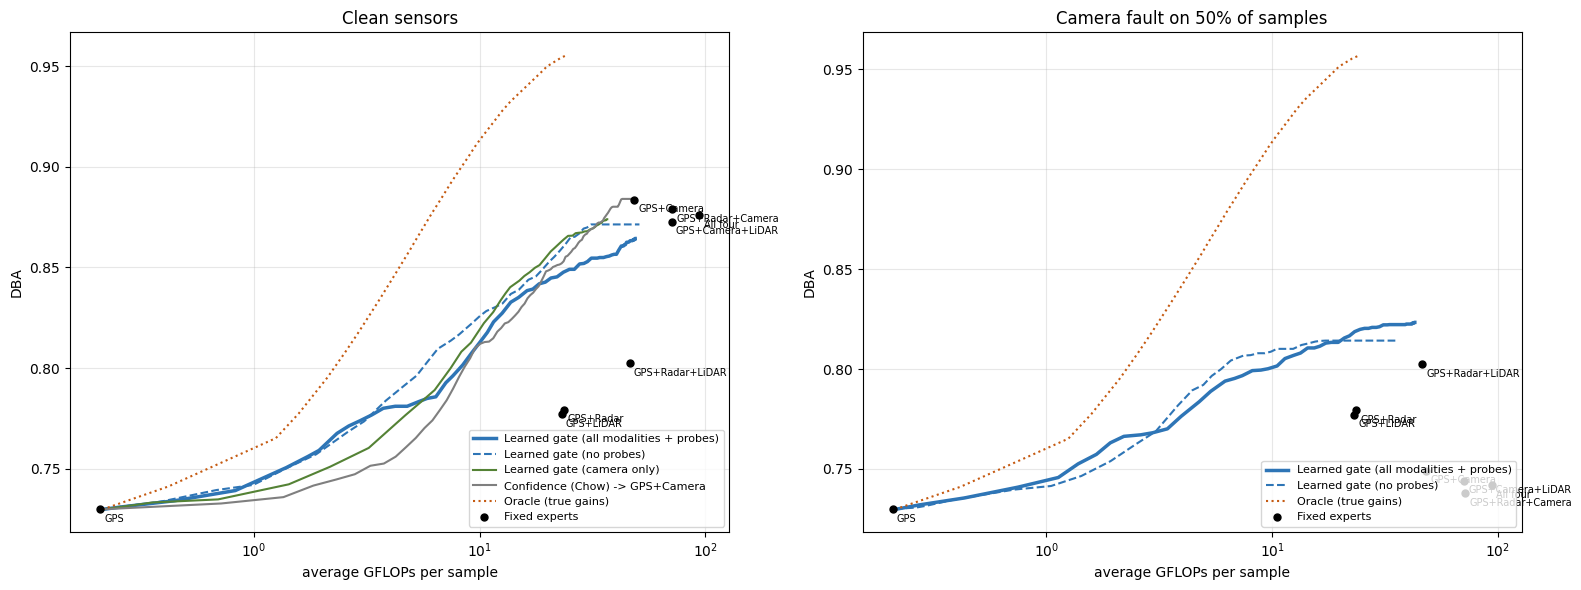

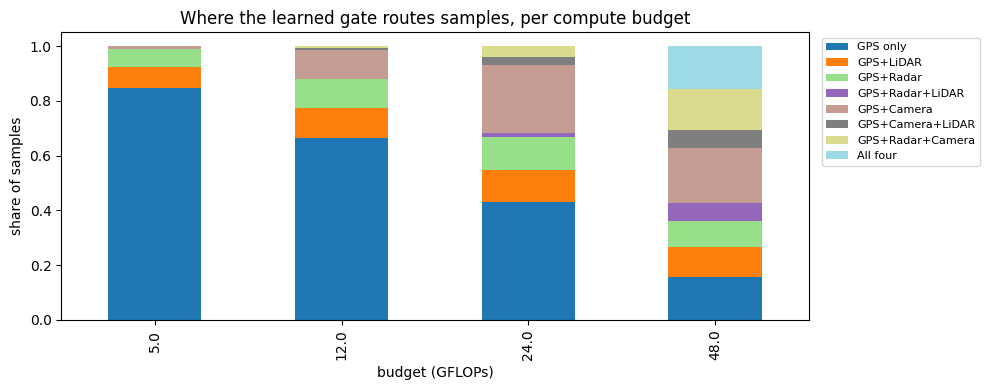

In [13]:
import matplotlib.pyplot as plt

STYLE = {"Learned gate (all modalities + probes)": dict(color="#2E75B6", lw=2.5),
         "Learned gate (no probes)": dict(color="#2E75B6", lw=1.5, ls="--"),
         "Learned gate (camera only)": dict(color="#548235", lw=1.5),
         "Confidence (Chow) -> GPS+Camera": dict(color="#7F7F7F", lw=1.5),
         "Oracle (true gains)": dict(color="#C55A11", lw=1.5, ls=":")}


def frontier(ax, curves, fixed, title):
    for name, df in curves.groupby("policy", sort=False):
        df = df.sort_values("GFLOPs")
        env = df.assign(DBA=df.DBA.cummax())
        ax.plot(env.GFLOPs, env.DBA, label=name, **STYLE.get(name, {}))
    ax.scatter(fixed.GFLOPs, fixed.DBA, color="black", zorder=5, s=25, label="Fixed experts")
    for _, r in fixed.iterrows():
        ax.annotate(r.policy, (r.GFLOPs, r.DBA), fontsize=7, xytext=(3, -9), textcoords="offset points")
    ax.set_xscale("symlog", linthresh=1.0)
    ax.set_xlabel("average GFLOPs per sample")
    ax.set_ylabel("DBA")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")


fig, axes = plt.subplots(1, 2, figsize=(16, 6))
frontier(axes[0], CURVES, FIXED, "Clean sensors")
frontier(axes[1], CURVES_M, FIXED_M, f"Camera fault on {100 * HEALTH_FRAC:.0f}% of samples")
plt.tight_layout()
plt.savefig(OUT / "plots" / "accuracy_vs_compute.png", dpi=150)
plt.show()

if len(ROUTING_MIX):
    ax = ROUTING_MIX.set_index("budget (GFLOPs)").drop(columns="lambda").plot.bar(
        stacked=True, figsize=(10, 4), colormap="tab20")
    ax.set_ylabel("share of samples")
    ax.set_title("Where the learned gate routes samples, per compute budget")
    ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(OUT / "plots" / "routing_mix.png", dpi=150)
    plt.show()

In [14]:
summary.to_csv(OUT / "experts.csv", index=False)
CURVES.to_csv(OUT / "curves_clean.csv", index=False)
CURVES_M.to_csv(OUT / "curves_camera_fault.csv", index=False)
BUDGET_TABLE.to_csv(OUT / "budget_table_clean.csv", index=False)
HEALTH_TABLE.to_csv(OUT / "budget_table_camera_fault.csv", index=False)
HEALTH_ROUTING.to_csv(OUT / "health_routing.csv", index=False)
ROUTING_MIX.to_csv(OUT / "routing_mix.csv", index=False)
ROUTER_LOG.to_csv(OUT / "router_log.csv", index=False)
pd.DataFrame({"sample_id": T.sample_id, "fold": FOLDS,
              **{f"ghat__{s}": GHAT[:, k] for k, s in enumerate(EXPERTS)},
              **{f"g__{s}": G[:, k] for k, s in enumerate(EXPERTS)}}).to_csv(
    OUT / "gate_predictions_clean.csv", index=False)
torch.save({"experts": EXPERTS, "f0": F0, "features": FEATS, "lambda": LAMBDA,
            "cost": COST.tolist(),
            "gates": [{"state_dict": g.state_dict(), "mu": mu, "sd": sd}
                      for _p, g, mu, sd in FINAL_FITS]}, OUT / "modality_gate.pt")
meta = {"quick_run": QUICK_RUN, "split": SPLIT, "n_samples": int(len(T)),
        "f0": F0, "experts": EXPERTS, "gflops": GFLOPS, "c_probe": C_PROBE,
        "features": FEATS, "features_no_probe": FEATS_NOPROBE, "dropped_constant": DROPPED,
        "gate": {"hidden": GATE_HIDDEN, "epochs": GATE_EPOCHS, "seeds": GATE_SEEDS,
                 "parameters": int(n_par), "objective": "MSE on per-expert DBA gain"},
        "cross_fit": {"folds": N_FOLDS, "block_frames": BLOCK_FRAMES},
        "health_fault": list(HEALTH_FAULT), "health_frac": HEALTH_FRAC,
        "router_lambda": LAMBDA}
(OUT / "config.json").write_text(json.dumps(meta, indent=2, default=str))
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUT)}  ({p.stat().st_size / 1e3:.1f} KB)")

  budget_table_camera_fault.csv  (0.5 KB)
  budget_table_clean.csv  (0.7 KB)
  config.json  (1.8 KB)
  curves_camera_fault.csv  (45.0 KB)
  curves_clean.csv  (69.5 KB)
  experts.csv  (0.8 KB)
  gate_predictions_clean.csv  (584.5 KB)
  health_routing.csv  (0.2 KB)
  modality_gate.pt  (58.3 KB)
  plots/accuracy_vs_compute.png  (190.2 KB)
  plots/routing_mix.png  (54.7 KB)
  router_log.csv  (22.8 KB)
  routing_mix.csv  (0.8 KB)
  table_clean.csv  (1360.6 KB)
  table_fault_image_blur_2.csv  (1366.2 KB)
